# Keppetipola Wholesale Vegetable Prices (2024-2026) - Reproducible Pipeline

Generates:
1. `keppetipola_wholesale_vegetable_prices_2024_2026.csv`
2. `vegetable_price_trends_2024_2026.png`

### 1. Configuration & Environment Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Auto-detect Google Colab vs. local execution
DATA_DIR = "/RawData/"
OUTPUT_DIR = DATA_DIR

# ---------------------------------------
## How to Cite
# If you use this dataset, please cite it as follows:

# ```bibtex
# @misc{keppetipola_vegetable_prices_2024_2026,
#   author = {Anton Jayakody},
#   title = {Keppetipola Wholesale Vegetable Prices Dataset (2024-2026)},
#   year = {2026},
#   publisher = {Zenodo},
#   doi = {https://doi.org/10.5281/zenodo.24214018},
#   url = {https://github.com/tobijay666/Sri-Lankan-Agri-Food-Economic-Open-Data OR https://zenodo.org/records/24214018}
# }
# ```
# ---------------------------------------

EXCEL_FILES = [
    (os.path.join(DATA_DIR, "2024 Veg Prices.xlsx"), 2024),
    (os.path.join(DATA_DIR, "2025 Veg Prices.xlsx"), 2025),
    (os.path.join(DATA_DIR, "2026 Veg Prices.xlsx"), 2026),
]

### 2. Parse & Compile Raw Excel Bulletins (Wide-to-Long)

In [2]:
veg_translation = {
    "ලීක්ස්": "Leeks",
    "කැරට්": "Carrot",
    "ගෝවා": "Cabbage",
    "තක්කාලි": "Tomato",
    "බෝංචි": "Beans",
    "අර්තාපල්": "Potato",
    "ලූණු": "Onion",
    "රතු ලූණු": "Red Onion",
    "බිග් ලූණු": "Big Onion",
    "අමු මිරිස්": "Green Chilli",
    "කරවිල": "Bitter Gourd",
    "වම්බටු": "Brinjal",
    "පතෝල": "Snake Gourd",
    "වැටකොළු": "Ridge Gourd",
    "පිපිඤ්ඤා": "Cucumber",
    "නෝකෝල්": "Knolkhol",
    "රාබු": "Radish",
    "බණ්ඩක්කා": "Ladies Fingers",
    "මෑකරල්": "Long Beans",
    "දෙහි": "Lime",
    "කොස්": "Jackfruit",
    "පොල්": "Coconut",
    "beetroot": "Beetroot",
    "berinjal": "Brinjal",
    "cabbage leef": "Cabbage Leaf",
    "capsicum": "Capsicum",
    "carrot": "Carrot",
    "green chillie": "Green Chilli",
    "green chilies": "Green Chilli",
    "knokol": "Knolkhol",
    "leeks": "Leeks",
    "lime": "Lime",
    "potato- local": "Potato (Local)",
    "red onion - local": "Red Onion (Local)",
    "tomato": "Tomato",
}

def clean_veg_name(name):
    if not isinstance(name, str):
        return np.nan
    name_clean = name.strip().lower()
    for raw_term, standard_name in veg_translation.items():
        if raw_term.lower() in name_clean:
            return standard_name
    return name.strip().title()

compiled_records = []

for file_path, year in EXCEL_FILES:
    if not os.path.exists(file_path):
        print(f"Warning: File not found, skipping -> {file_path}")
        continue

    xl = pd.ExcelFile(file_path)
    for sheet_name in xl.sheet_names:
        if "average" in sheet_name.lower() or "සාරාංශය" in sheet_name.lower():
            continue

        df_raw = xl.parse(sheet_name, header=None)

        # Locate the header row containing date strings
        date_row_idx = None
        for idx, row in df_raw.iterrows():
            dates_found = (
                row.astype(str).str.contains(r"\d{4}[\./-]\d{2}[\./-]\d{2}", regex=True).sum()
            )
            if dates_found > 1:
                date_row_idx = idx
                break

        if date_row_idx is None:
            date_row_idx = 1 if len(df_raw) > 1 else 0

        headers = [
            f"Col_{i}" if pd.isna(h) else h
            for i, h in enumerate(df_raw.iloc[date_row_idx].tolist())
        ]

        df_data = df_raw.iloc[date_row_idx + 1 :].copy()

        df_data.columns = headers
        df_data = df_data.rename(columns={df_data.columns[0]: "Vegetable"})
        df_data["Vegetable"] = df_data["Vegetable"].apply(clean_veg_name)
        df_data = df_data.dropna(subset=["Vegetable"])

        date_cols = [
            col
            for col in df_data.columns
            if col != "Vegetable" and not str(col).startswith("Col_")
        ]

        for date_col in date_cols:
            date_standardized = str(date_col).strip().replace(".", "-").split(" ")[0]
            for _, row in df_data.iterrows():
                veg_val = row["Vegetable"]
                price_val = row[date_col]

                if isinstance(price_val, pd.Series):
                    price_val = price_val.iloc[0]
                if isinstance(veg_val, pd.Series):
                    veg_val = veg_val.iloc[0]

                try:
                    price_num = float(price_val)
                except (ValueError, TypeError):
                    price_num = np.nan

                if pd.notna(price_num) and pd.notna(veg_val) and str(veg_val).strip():
                    compiled_records.append(
                        {
                            "Date": date_standardized,
                            "Year": year,
                            "Vegetable": veg_val,
                            "Price_LKR": price_num,
                        }
                    )

master_df = pd.DataFrame(compiled_records)
master_df = master_df[
    master_df["Date"].astype(str).str.contains(r"\d{4}-\d{2}-\d{2}", regex=True, na=False)
]
master_df["Date"] = pd.to_datetime(master_df["Date"], errors="coerce")
master_df = master_df.dropna(subset=["Date"]).reset_index(drop=True)
print(f"Compiled {len(master_df)} raw price observations.")

Compiled 6815 raw price observations.


### 3. Clean Anomalies, Standardize Taxonomy, & Flag Carried-Forward Days

In [3]:
df_clean = master_df.sort_values(by=["Date", "Vegetable"]).reset_index(drop=True)
df_clean["Price_Raw_LKR"] = df_clean["Price_LKR"]
df_clean["Price_Clean_LKR"] = df_clean["Price_LKR"]
df_clean["Correction_Notes"] = "None"

def apply_correction(df, date_str, veg_name, correct_val, notes):
    mask = (df["Date"] == pd.to_datetime(date_str)) & (df["Vegetable"] == veg_name)
    if mask.any():
        df.loc[mask, "Price_Clean_LKR"] = float(correct_val)
        df.loc[mask, "Correction_Notes"] = notes

# Documented typo & parsing-error corrections
apply_correction(df_clean, "2024-01-28", "Tomato", 500, "Corrected 5000 to 500 (10x typo)")
apply_correction(df_clean, "2026-03-08", "Beetroot", 110, "Corrected 11 to 110 (dropped zero)")
apply_correction(df_clean, "2026-05-24", "Tomato", 250, "Corrected 25 to 250 (dropped zero)")
apply_correction(df_clean, "2025-02-12", "Green Chilli", 1100, "Corrected 100 to 1100 (likely dropped zero/typo)")
apply_correction(df_clean, "2025-02-13", "Green Chilli", 1100, "Corrected 100 to 1100 (likely dropped zero/typo)")

potato_dates = ["2025-10-03", "2025-10-05", "2025-10-25", "2025-10-26", "2025-10-27", "2025-11-24"]
for d in potato_dates:
    mask = (df_clean["Date"] == pd.to_datetime(d)) & (df_clean["Vegetable"] == "Potato")
    if mask.any():
        corrected_val = df_clean.loc[mask, "Price_Raw_LKR"].iloc[0] + 100.0
        apply_correction(df_clean, d, "Potato", corrected_val, "Added leading digit 100 (corrected parsing drop)")

apply_correction(df_clean, "2026-01-05", "Potato", 250.0, "Corrected 100 to 250 based on temporal context (250 on Jan 4, 300 on Jan 6)")
apply_correction(df_clean, "2026-02-13", "Pumpkin", 105.0, "Corrected 30 to 105 based on temporal context (110 on Feb 12, 100 on Feb 14)")
apply_correction(df_clean, "2024-01-13", "Capsicum", 500.0, "Corrected 200 to 500 based on temporal context (500 on Jan 12, 500 on Jan 14)")
apply_correction(df_clean, "2025-04-07", "Capsicum", 600.0, "Corrected 200 to 600 based on temporal context (600 on Apr 5, 600 on Apr 8)")

# Taxonomy & Metadata
standard_botanical_names = {
    "Leeks": "Allium ampeloprasum",
    "Carrot": "Daucus carota",
    "Cabbage": "Brassica oleracea var. capitata",
    "Tomato": "Solanum lycopersicum",
    "Beans": "Phaseolus vulgaris",
    "Potato": "Solanum tuberosum",
    "Potato (Local)": "Solanum tuberosum (Local)",
    "Onion": "Allium cepa",
    "Red Onion": "Allium cepa var. aggregatum",
    "Red Onion (Local)": "Allium cepa var. aggregatum (Local)",
    "Big Onion": "Allium cepa (Large)",
    "Green Chilli": "Capsicum annuum (Chili pepper group)",
    "Bitter Gourd": "Momordica charantia",
    "Brinjal": "Solanum melongena",
    "Snake Gourd": "Trichosanthes cucumerina",
    "Ridge Gourd": "Luffa acutangula",
    "Cucumber": "Cucumis sativus",
    "Knolkhol": "Brassica oleracea var. gongylodes",
    "Radish": "Raphanus sativus",
    "Ladies Fingers": "Abelmoschus esculentus",
    "Long Beans": "Vigna unguiculata subsp. sesquipedalis",
    "Lime": "Citrus aurantiifolia",
    "Jackfruit": "Artocarpus heterophyllus",
    "Coconut": "Cocos nucifera",
    "Beetroot": "Beta vulgaris",
    "Cabbage Leaf": "Brassica oleracea (Foliage)",
    "Capsicum": "Capsicum annuum (Capsicum Group)",
    "Pumpkin": "Cucurbita maxima",
    "Salada": "Lactuca sativa",
}

english_name_mapping = {
    "Leeks": "Leeks",
    "Carrot": "Carrot",
    "Cabbage": "Cabbage",
    "Tomato": "Tomato",
    "Beans": "Green Beans",
    "Potato": "Potato",
    "Potato (Local)": "Local Potato",
    "Onion": "Onion",
    "Red Onion": "Red Onion",
    "Red Onion (Local)": "Local Red Onion",
    "Big Onion": "Big Onion",
    "Green Chilli": "Green Chilli",
    "Bitter Gourd": "Bitter Gourd",
    "Brinjal": "Eggplant / Brinjal",
    "Snake Gourd": "Snake Gourd",
    "Ridge Gourd": "Ridge Gourd",
    "Cucumber": "Cucumber",
    "Knolkhol": "Kohlrabi / Knol-khol",
    "Radish": "Radish",
    "Ladies Fingers": "Okra / Ladies Fingers",
    "Long Beans": "Yardlong Beans",
    "Lime": "Lime",
    "Jackfruit": "Jackfruit",
    "Coconut": "Coconut",
    "Beetroot": "Beetroot",
    "Cabbage Leaf": "Cabbage Leaf",
    "Capsicum": "Bell Pepper / Capsicum",
    "Pumpkin": "Pumpkin",
    "Salada": "Lettuce / Salada",
}

df_clean["Botanical_Name"] = df_clean["Vegetable"].map(standard_botanical_names).fillna("Unknown/Other")
df_clean["English_Name"] = df_clean["Vegetable"].map(english_name_mapping).fillna(df_clean["Vegetable"])
df_clean["Unit"] = "LKR/kg"
df_clean["Market_Type"] = "Wholesale"

# Flag consecutive dates with identical price profiles across all active crops
df_pivot_sorted = df_clean.pivot(index="Date", columns="Vegetable", values="Price_Clean_LKR").sort_index()
carried_forward_dates = set()
previous_row = None

for i, (date, row) in enumerate(df_pivot_sorted.iterrows()):
    if i > 0:
        common_cols = row.index[row.notna() & previous_row.notna()]
        if len(common_cols) > 0 and (row[common_cols] == previous_row[common_cols]).all():
            carried_forward_dates.add(date)
    previous_row = row

df_clean["Data_Quality_Flag"] = "Observed"
df_clean.loc[df_clean["Date"].isin(carried_forward_dates), "Data_Quality_Flag"] = "Carried_Forward"

# Enforce clean column order and drop redundant columns
final_cols = [
    "Date",
    "Vegetable",
    "Price_Raw_LKR",
    "Price_Clean_LKR",
    "Correction_Notes",
    "Botanical_Name",
    "English_Name",
    "Unit",
    "Market_Type",
    "Data_Quality_Flag",
]
df_clean = df_clean[final_cols]

final_csv_path = os.path.join(OUTPUT_DIR, "keppetipola_wholesale_vegetable_prices_2024_2026.csv")
df_clean.to_csv(final_csv_path, index=False)
print(f"Saved cleaned dataset: {final_csv_path} ({len(df_clean)} rows)")

Saved cleaned dataset: /content/keppetipola_wholesale_vegetable_prices_2024_2026.csv (6815 rows)


### 4. Publication-Ready Descriptive Visualization (Using Cleaned Prices)

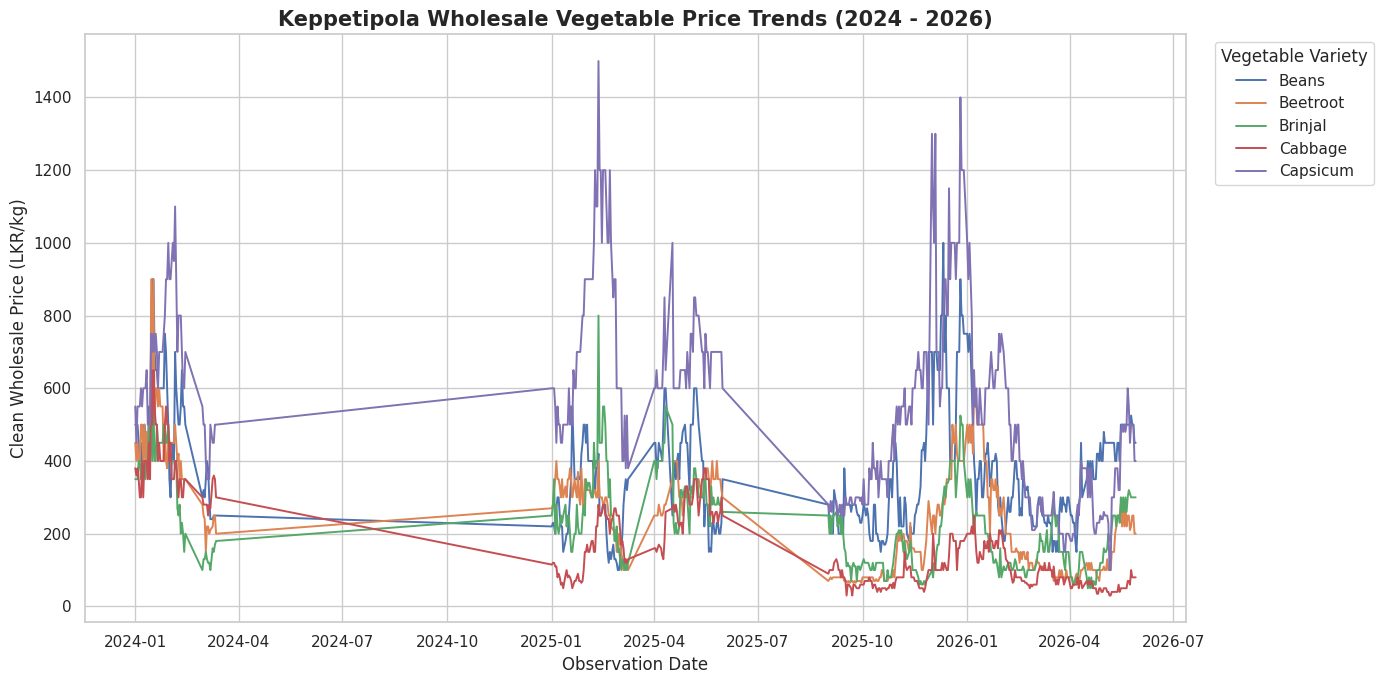

In [8]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

top_vegs = df_clean["Vegetable"].value_counts().head(5).index.tolist()
df_plot = df_clean[df_clean["Vegetable"].isin(top_vegs)].sort_values("Date")

sns.lineplot(data=df_plot, x="Date", y="Price_Clean_LKR", hue="Vegetable", linewidth=1.4)
plt.title("Keppetipola Wholesale Vegetable Price Trends (2024 - 2026)", fontsize=15, fontweight="bold")
plt.xlabel("Observation Date", fontsize=12)
plt.ylabel("Clean Wholesale Price (LKR/kg)", fontsize=12)
plt.legend(title="Vegetable Variety", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plot_path = os.path.join(OUTPUT_DIR, "vegetable_price_trends_2024_2026.png")
plt.savefig(plot_path, dpi=300)
plt.show()
plt.close()